# TV1 — Console Dataset ETL

This notebook preprocesses only the VGChartz Console dataset and exports `data/processed/vgchartz_cleaned.csv`.

> **Input-location note:** the project documentation specifies `data/raw/vgchartz_games.csv`, but the inspected repository currently stores the file at its root. The load cell checks the documented path first, then safely falls back to the root-level file.

## 1. Load and Inspect Data

Load the source, confirm its schema, and retain all original columns.

In [68]:
from pathlib import Path
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

documented_input = os.path.join('..', '..', 'data', 'raw', 'vgchartz_games.csv')

df = pd.read_csv(documented_input)
rows_before = len(df)
print(f"Loaded {rows_before:,} rows from: {documented_input}")
display(df.head())
print(df.dtypes)
print("Columns:", df.columns.tolist())
print(df["console"].unique())

Loaded 64,154 rows from: ..\..\data\raw\vgchartz_games.csv


,img,title,console,genre,publisher,developer,critic_score,total_shipped,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update
0,/games/boxart/full_6510540AmericaFrontccc.jpg,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,NaN,20.32,6.37,0.99,9.85,3.12,2013-09-17,NaN
1,/games/boxart/full_5563178AmericaFrontccc.jpg,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,NaN,19.39,6.06,0.60,9.71,3.02,2014-11-18,2018-01-03
2,/games/boxart/827563ccc.jpg,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,NaN,16.15,8.41,0.47,5.49,1.78,2002-10-28,NaN
3,/games/boxart/full_9218923AmericaFrontccc.jpg,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,NaN,15.86,9.06,0.06,5.33,1.42,2013-09-17,NaN
4,/games/boxart/full_4990510AmericaFrontccc.jpg,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,NaN,15.09,6.18,0.41,6.05,2.44,2015-11-06,2018-01-14


img                  str
title                str
console              str
genre                str
publisher            str
developer            str
critic_score     float64
total_shipped    float64
total_sales      float64
na_sales         float64
jp_sales         float64
pal_sales        float64
other_sales      float64
release_date         str
last_update          str
dtype: object
Columns: ['img', 'title', 'console', 'genre', 'publisher', 'developer', 'critic_score', 'total_shipped', 'total_sales', 'na_sales', 'jp_sales', 'pal_sales', 'other_sales', 'release_date', 'last_update']
<ArrowStringArray>
[   'PS3',    'PS4',    'PS2',   'X360',   'XOne',     'PC',    'PSP',
    'Wii',     'PS',     'DS',   '2600',    'GBA',    'NES',     'XB',
    'PSN',    'GEN',    'PSV',     'DC',    'N64',    'SAT',   'SNES',
    'GBC',     'GC',     'NS',    '3DS',     'GB',   'WiiU',     'WS',
     'VC',     'NG',     'WW',    'SCD',    'PCE',    'XBL',    '3DO',
     'GG',    'OSX',    'Mob',   '

## 2. Process Sales Data and Filter Non-Console Platforms

Rows are removed only when both `total_shipped` and `total_sales` are missing. A new `Volume_Units` column is calculated using `total_sales`; when `total_sales` is unavailable, `total_shipped` is used instead.

Non-console platforms, including `PC`, `Android`, `iOS`, and mobile platforms, are excluded from the dataset.

In [36]:
df = df.dropna(
    subset=["total_sales", "total_shipped"],
    how="all"
).copy()

df['volume_millions'] = df['total_sales'].fillna(df['total_shipped'])
df["Volume_Units"] = df['volume_millions'] * 1_000_000
df[["total_shipped", "total_sales", "Volume_Units"]].head()

invalid_consoles = ["PC", "And", "iOS", "Mob"]

df = df[df["console"].notna() & ~df["console"].isin(invalid_consoles)].copy()

regional_cols = ["na_sales", "pal_sales", "jp_sales", "other_sales"]
for col in regional_cols:
      df[col] = df[col].fillna(0.0)
df = df.rename(
    columns={"console": "platform", "pal_sales": "eu_sales"}
)


## 3. Normalize Release Date


In [37]:
df["release_date"] = pd.to_datetime(
    df["release_date"], errors="coerce"
)

df["release_year"] = df["release_date"].dt.year.astype("Int64")

df[["release_date", "release_year"]].head()

,release_date,release_year
0,2013-09-17,2013
1,2014-11-18,2014
2,2002-10-28,2002
3,2013-09-17,2013
4,2015-11-06,2015


## 4. Calculate MSRP and Harmonized Revenue

`MSRP_USD` is a project-defined, standardized estimate: $50 through 2005, $60 for 2006–2020, and $70 from 2021. `Estimated_Revenue_USD` is therefore not actual historical revenue; it is a comparable estimate based on shipped volume and the assigned MSRP.

In [38]:
df["MSRP_USD"] = pd.Series(pd.NA, index=df.index, dtype="Float64")
df.loc[df["release_year"] <= 2005, "MSRP_USD"] = 50.0
df.loc[df["release_year"].between(2006, 2020), "MSRP_USD"] = 60.0
df.loc[df["release_year"] >= 2021, "MSRP_USD"] = 70.0
df["Estimated_Revenue_USD"] = df["Volume_Units"] * df["MSRP_USD"]
df[["release_year", "Volume_Units", "MSRP_USD", "Estimated_Revenue_USD"]].head()

,release_year,Volume_Units,MSRP_USD,Estimated_Revenue_USD
0,2013,20320000.0,60.0,1219200000.0
1,2014,19390000.0,60.0,1163400000.0
2,2002,16150000.0,50.0,807500000.0
3,2013,15860000.0,60.0,951600000.0
4,2015,15090000.0,60.0,905400000.0


## 5. Process Critic Score

The inspected `Critic Score` values are on a 0–10 scale and use `N/A` for missing data. Missing scores are imputed from the median valid score of the exact corresponding `Genre`; genres with no valid score remain missing. The original column is preserved.

Standardized_Rating này không thực sự cần thiết nếu sau này bạn muốn so sánh:

PC vs Console vs Mobile

Bởi vì:

Critic Score của VGChartz là một loại điểm đánh giá.
Steam có thể có positive/negative reviews.
Mobile có star rating.

Ba loại điểm này không phải cùng một thước đo.
Console: Critic Score = 80
Steam: Positive Ratio = 80%
Mobile: Rating = 4.0/5

Không thể nói đơn giản rằng cả ba đều tương đương với "80/100".

Vì vậy, trong project của bạn, mình sẽ không khuyến nghị dùng Standardized_Rating làm biến chính để so sánh PC/Console/Mobile.

In [39]:
critic_numeric = pd.to_numeric(df["critic_score"], errors="coerce")
print(critic_numeric.describe())

genre_median_critic = critic_numeric.groupby(df["genre"]).transform("median")
critic_imputed = critic_numeric.fillna(genre_median_critic)
df["Rating"] = critic_imputed * 10
df[["genre", "critic_score", "Rating"]].head(10)

def get_tier(score):
  if score >= 85.0:
    return 'Masterpiece'
  elif score >= 75.0:
    return 'Great'
  elif score >= 50.0:
    return 'Mixed'
  else:
    return 'Poor'

df['Rating_Tier'] = df['Rating'].apply(get_tier)

count    3787.000000
mean        7.065091
std         1.439642
min         1.000000
25%         6.300000
50%         7.300000
75%         8.100000
max        10.000000
Name: critic_score, dtype: float64


## 6. Create Console_Maker and Console_Gen

Mappings use the actual `Platform` codes. Only platforms explicitly named by the task receive a console-generation label; unsupported, non-console, aggregate, and older platforms remain missing for `Console_Gen` and are `Other` for `Console_Maker`.

In [40]:
print(sorted(df["platform"].dropna().unique()))

sony_platforms = {"PS", "PS2", "PS3", "PS4", "PS5", "PSP", "PSV", "PSN"}
microsoft_platforms = {"XB", "X360", "XOne", "XS", "XBL"}
nintendo_platforms = {"NES", "SNES", "N64", "GC", "Wii", "WiiU", "NS", "NS2", "GB", "GBC", "GBA", "DS", "3DS"}

def console_maker(platform):
    if platform in sony_platforms:
        return "Sony"
    if platform in microsoft_platforms:
        return "Microsoft"
    if platform in nintendo_platforms:
        return "Nintendo"
    return "Other"

generation_map = {
    "PS2": "Gen 6", "XB": "Gen 6", "GC": "Gen 6",
    "PS3": "Gen 7", "X360": "Gen 7", "Wii": "Gen 7",
    "PS4": "Gen 8", "XOne": "Gen 8", "NS": "Gen 8", "WiiU": "Gen 8",
    "PS5": "Gen 9", "XS": "Gen 9",
}

df["Console_Maker"] = df["platform"].map(console_maker)
df["Console_Gen"] = df["platform"].map(generation_map).astype("string")
df[["platform", "Console_Maker", "Console_Gen"]].head(10)
df

['2600', '3DO', '3DS', 'All', 'DC', 'DS', 'GB', 'GBA', 'GBC', 'GC', 'GEN', 'GG', 'N64', 'NES', 'NG', 'NS', 'NS2', 'OSX', 'PCE', 'PCFX', 'PS', 'PS2', 'PS3', 'PS4', 'PS5', 'PSN', 'PSP', 'PSV', 'SAT', 'SCD', 'SNES', 'Series', 'VC', 'WS', 'WW', 'Wii', 'WiiU', 'X360', 'XB', 'XBL', 'XOne', 'XS']


,img,title,platform,genre,publisher,developer,critic_score,total_shipped,total_sales,na_sales,...,last_update,volume_millions,Volume_Units,release_year,MSRP_USD,Estimated_Revenue_USD,Rating,Rating_Tier,Console_Maker,Console_Gen
0,/games/boxart/full_6510540AmericaFrontccc.jpg,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,NaN,20.32,6.37,...,NaN,20.32,20320000.0,2013,60.0,1219200000.0,94.0,Masterpiece,Sony,Gen 7
1,/games/boxart/full_5563178AmericaFrontccc.jpg,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,NaN,19.39,6.06,...,2018-01-03,19.39,19390000.0,2014,60.0,1163400000.0,97.0,Masterpiece,Sony,Gen 8
2,/games/boxart/827563ccc.jpg,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,NaN,16.15,8.41,...,NaN,16.15,16150000.0,2002,50.0,807500000.0,96.0,Masterpiece,Sony,Gen 6
3,/games/boxart/full_9218923AmericaFrontccc.jpg,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,NaN,15.86,9.06,...,NaN,15.86,15860000.0,2013,60.0,951600000.0,68.0,Mixed,Microsoft,Gen 7
4,/games/boxart/full_4990510AmericaFrontccc.jpg,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,NaN,15.09,6.18,...,2018-01-14,15.09,15090000.0,2015,60.0,905400000.0,81.0,Great,Sony,Gen 8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64147,NaN,Fairy Tail 2,All,"Action, RPG",Koei Tecmo,Koei Tecmo Games,NaN,0.12,NaN,0.00,...,2025-01-27,0.12,120000.0,2024,70.0,8400000.0,85.0,Masterpiece,Other,<NA>
64149,NaN,Fate/stay night Remastered,All,Adventure,Aniplex Inc.,Type-Moon,NaN,0.10,NaN,0.00,...,2024-12-20,0.10,100000.0,2024,70.0,7000000.0,70.5,Mixed,Other,<NA>
64150,NaN,Urban Myth Dissolution Center,All,Adventure,SHUEISHA GAMES,Hakababunko,NaN,0.10,NaN,0.00,...,2025-02-26,0.10,100000.0,2025,70.0,7000000.0,70.5,Mixed,Other,<NA>
64151,NaN,Tormented Souls 2,All,"Adventure, Action",PQube,Dual Effect,NaN,0.10,NaN,0.00,...,2025-11-29,0.10,100000.0,2025,70.0,7000000.0,NaN,Poor,Other,<NA>


## 7. Basic Validation

Confirm row preservation, important missing values, new-column types, representative rows, and mapping counts.

In [41]:
df['Game_Title'] = df['title']
df['Platform_Category'] = 'Console'

new_columns = ["Volume_Units", "release_year", "MSRP_USD", "Estimated_Revenue_USD", "Rating", "Rating_Tier", "Console_Maker", "Console_Gen"]
print("\nMissing values:")
print("\nNew column data types:")
print(df[new_columns].dtypes)
print("\nConsole maker counts:")
print(df["Console_Maker"].value_counts(dropna=False))
print("\nConsole generation counts:")
print(df["Console_Gen"].value_counts(dropna=False))
display(df[["Game_Title", "platform", "total_shipped","total_sales", "Volume_Units", "release_date", "release_year", "Rating", "Rating_Tier", "Console_Maker", "Console_Gen"]].head())
df


Missing values:

New column data types:
Volume_Units             float64
release_year               Int64
MSRP_USD                 Float64
Estimated_Revenue_USD    Float64
Rating                   float64
Rating_Tier                  str
Console_Maker                str
Console_Gen               string
dtype: object

Console maker counts:
Console_Maker
Sony         7575
Nintendo     6816
Microsoft    2674
Other         693
Name: count, dtype: int64

Console generation counts:
Console_Gen
<NA>     8302
Gen 7    4007
Gen 6    3490
Gen 8    1947
Gen 9      12
Name: count, dtype: int64[pyarrow]


,Game_Title,platform,total_shipped,total_sales,Volume_Units,release_date,release_year,Rating,Rating_Tier,Console_Maker,Console_Gen
0,Grand Theft Auto V,PS3,NaN,20.32,20320000.0,2013-09-17,2013,94.0,Masterpiece,Sony,Gen 7
1,Grand Theft Auto V,PS4,NaN,19.39,19390000.0,2014-11-18,2014,97.0,Masterpiece,Sony,Gen 8
2,Grand Theft Auto: Vice City,PS2,NaN,16.15,16150000.0,2002-10-28,2002,96.0,Masterpiece,Sony,Gen 6
3,Grand Theft Auto V,X360,NaN,15.86,15860000.0,2013-09-17,2013,68.0,Mixed,Microsoft,Gen 7
4,Call of Duty: Black Ops 3,PS4,NaN,15.09,15090000.0,2015-11-06,2015,81.0,Great,Sony,Gen 8


,img,title,platform,genre,publisher,developer,critic_score,total_shipped,total_sales,na_sales,...,Volume_Units,release_year,MSRP_USD,Estimated_Revenue_USD,Rating,Rating_Tier,Console_Maker,Console_Gen,Game_Title,Platform_Category
0,/games/boxart/full_6510540AmericaFrontccc.jpg,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,NaN,20.32,6.37,...,20320000.0,2013,60.0,1219200000.0,94.0,Masterpiece,Sony,Gen 7,Grand Theft Auto V,Console
1,/games/boxart/full_5563178AmericaFrontccc.jpg,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,NaN,19.39,6.06,...,19390000.0,2014,60.0,1163400000.0,97.0,Masterpiece,Sony,Gen 8,Grand Theft Auto V,Console
2,/games/boxart/827563ccc.jpg,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,NaN,16.15,8.41,...,16150000.0,2002,50.0,807500000.0,96.0,Masterpiece,Sony,Gen 6,Grand Theft Auto: Vice City,Console
3,/games/boxart/full_9218923AmericaFrontccc.jpg,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,NaN,15.86,9.06,...,15860000.0,2013,60.0,951600000.0,68.0,Mixed,Microsoft,Gen 7,Grand Theft Auto V,Console
4,/games/boxart/full_4990510AmericaFrontccc.jpg,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,NaN,15.09,6.18,...,15090000.0,2015,60.0,905400000.0,81.0,Great,Sony,Gen 8,Call of Duty: Black Ops 3,Console
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64147,NaN,Fairy Tail 2,All,"Action, RPG",Koei Tecmo,Koei Tecmo Games,NaN,0.12,NaN,0.00,...,120000.0,2024,70.0,8400000.0,85.0,Masterpiece,Other,<NA>,Fairy Tail 2,Console
64149,NaN,Fate/stay night Remastered,All,Adventure,Aniplex Inc.,Type-Moon,NaN,0.10,NaN,0.00,...,100000.0,2024,70.0,7000000.0,70.5,Mixed,Other,<NA>,Fate/stay night Remastered,Console
64150,NaN,Urban Myth Dissolution Center,All,Adventure,SHUEISHA GAMES,Hakababunko,NaN,0.10,NaN,0.00,...,100000.0,2025,70.0,7000000.0,70.5,Mixed,Other,<NA>,Urban Myth Dissolution Center,Console
64151,NaN,Tormented Souls 2,All,"Adventure, Action",PQube,Dual Effect,NaN,0.10,NaN,0.00,...,100000.0,2025,70.0,7000000.0,NaN,Poor,Other,<NA>,Tormented Souls 2,Console


## 8. Standardize Gerne and new columns for cleaned data


In [42]:
main_genre = {
    "Action",
    "Arcade",
    "Casino",
    "Lifestyle",
    "Puzzle",
    "RPG",
    "Racing",
    "Simulation",
    "Sports",
    "Strategy",
    "Shooter",
    "Tabletop",
}

genre_mapping = {
    "Action": "Action",
    "Adventure": "Action",
    "Fighting": "Action",
    "Platformer": "Arcade",
    "RPG": "RPG",
    "Strategy": "Strategy",
    "Puzzle": "Puzzle",
    "Casual": "Puzzle",
    "Simulation": "Simulation",
    "Shooter": "Shooter",
    "FPS": "Shooter",
    "Sports": "Sports",
    "Racing": "Racing",
    "Arcade": "Arcade",
    "Board Games": "Tabletop",
    "Card": "Tabletop",
}
genre_priority = [
    "Shooter",
    "RPG",
    "Strategy",
    "Simulation",
    "Racing",
    "Sports",
    "Puzzle",
    "Arcade",
    "Action",
    "Tabletop",
]

def map_genre(value):
      if pd.isna(value):
            return "Other"

      raw_genres = [
        genre.strip()
        for genre in str(value).split(",")
      ]

      mapped_genres = {
            genre_mapping[genre]
            for genre in raw_genres
            if genre in genre_mapping
      }

      # Chọn genre theo thứ tự ưu tiên
      for genre in genre_priority:
            if genre in mapped_genres:
                  return genre

      return "Other"
df['Genre'] = df['genre'].apply(map_genre)

df['IAP_Revenue_USD'] = 0.0
df['Paid_Revenue_USD'] = df['Estimated_Revenue_USD']
cols = ['Game_Title','Platform_Category','Genre',
    'publisher','developer','release_year','Volume_Units', 'IAP_Revenue_USD', 
    'Paid_Revenue_USD', 'Estimated_Revenue_USD','Rating','Rating_Tier', "Console_Maker", "Console_Gen"]

final_df = df[cols].copy()
df

,img,title,platform,genre,publisher,developer,critic_score,total_shipped,total_sales,na_sales,...,Estimated_Revenue_USD,Rating,Rating_Tier,Console_Maker,Console_Gen,Game_Title,Platform_Category,Genre,IAP_Revenue_USD,Paid_Revenue_USD
0,/games/boxart/full_6510540AmericaFrontccc.jpg,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,NaN,20.32,6.37,...,1219200000.0,94.0,Masterpiece,Sony,Gen 7,Grand Theft Auto V,Console,Action,0.0,1219200000.0
1,/games/boxart/full_5563178AmericaFrontccc.jpg,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,NaN,19.39,6.06,...,1163400000.0,97.0,Masterpiece,Sony,Gen 8,Grand Theft Auto V,Console,Action,0.0,1163400000.0
2,/games/boxart/827563ccc.jpg,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,NaN,16.15,8.41,...,807500000.0,96.0,Masterpiece,Sony,Gen 6,Grand Theft Auto: Vice City,Console,Action,0.0,807500000.0
3,/games/boxart/full_9218923AmericaFrontccc.jpg,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,NaN,15.86,9.06,...,951600000.0,68.0,Mixed,Microsoft,Gen 7,Grand Theft Auto V,Console,Action,0.0,951600000.0
4,/games/boxart/full_4990510AmericaFrontccc.jpg,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,NaN,15.09,6.18,...,905400000.0,81.0,Great,Sony,Gen 8,Call of Duty: Black Ops 3,Console,Shooter,0.0,905400000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64147,NaN,Fairy Tail 2,All,"Action, RPG",Koei Tecmo,Koei Tecmo Games,NaN,0.12,NaN,0.00,...,8400000.0,85.0,Masterpiece,Other,<NA>,Fairy Tail 2,Console,RPG,0.0,8400000.0
64149,NaN,Fate/stay night Remastered,All,Adventure,Aniplex Inc.,Type-Moon,NaN,0.10,NaN,0.00,...,7000000.0,70.5,Mixed,Other,<NA>,Fate/stay night Remastered,Console,Action,0.0,7000000.0
64150,NaN,Urban Myth Dissolution Center,All,Adventure,SHUEISHA GAMES,Hakababunko,NaN,0.10,NaN,0.00,...,7000000.0,70.5,Mixed,Other,<NA>,Urban Myth Dissolution Center,Console,Action,0.0,7000000.0
64151,NaN,Tormented Souls 2,All,"Adventure, Action",PQube,Dual Effect,NaN,0.10,NaN,0.00,...,7000000.0,NaN,Poor,Other,<NA>,Tormented Souls 2,Console,Action,0.0,7000000.0


## 9. Export Cleaned Dataset

Create the requested processed-data directory when needed and write the complete cleaned Console dataset.

In [43]:

output_path = os.path.join('..', '..', 'data', 'processed', 'console_cleaned.csv')
final_df.to_csv(output_path, index=False)
print(f"Exported {len(df):,} rows to: {output_path}")

Exported 17,758 rows to: ..\..\data\processed\console_cleaned.csv


In [44]:
columns = [
    "img",
    "title",
    "platform",
    "genre",
    "publisher",
    "developer",
    "critic_score",
    "total_sales",
    "na_sales",
    "jp_sales",
    "eu_sales",
    "other_sales",
    "release_date",
    "last_update",
    "Console_Maker",
    "Console_Gen",
    "Rating",
    "release_year",
]
df_filtered = df.loc[
    df["release_year"].between(2000, 2018),
    columns
].copy()

print("\nTOP 10 HỆ MÁY BÁN CHẠY NHẤT")
top_platforms = (
    df_filtered.groupby("platform")["total_sales"]
    .agg(["count", "sum"])
    .rename(columns={"count": "So_Game", "sum": "Tong_Ban_Ra_M_Ban"})
    .sort_values("Tong_Ban_Ra_M_Ban", ascending=False)
    .head(10)
)
print(top_platforms)


TOP 10 HỆ MÁY BÁN CHẠY NHẤT
          So_Game  Tong_Ban_Ra_M_Ban
platform                            
PS2          2119            1025.36
X360         1294             859.41
PS3          1338             838.66
PS4           884             538.47
Wii          1342             458.75
DS           2371             457.42
XOne          524             268.96
PSP          1326             243.68
XB            836             232.05
GBA           897             223.76


(array([0, 1, 2, 3]),
 [Text(0, 0, 'Microsoft'),
  Text(1, 0, 'Nintendo'),
  Text(2, 0, 'Other'),
  Text(3, 0, 'Sony')])

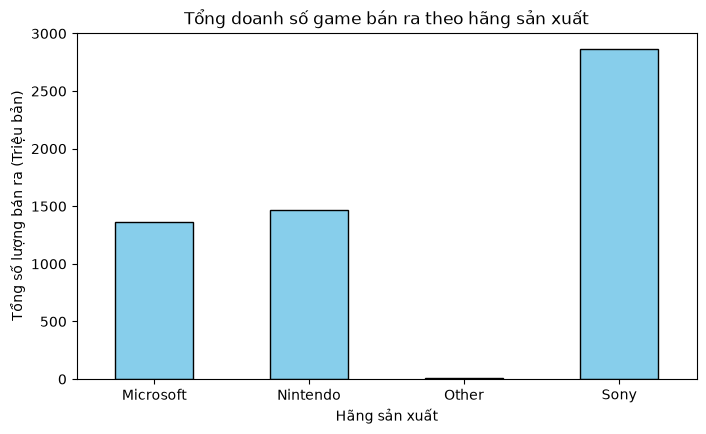

In [63]:
# Biểu đồ 1: Doanh số theo Hãng sản xuất
plt.figure(figsize=(8, 4.5))
df_filtered.groupby('Console_Maker')['total_sales'].sum().plot(
    kind='bar', color='skyblue', edgecolor='black'
)
plt.title('Tổng doanh số game bán ra theo hãng sản xuất')
plt.ylabel('Tổng số lượng bán ra (Triệu bản)')
plt.xlabel('Hãng sản xuất')
plt.xticks(rotation=0)

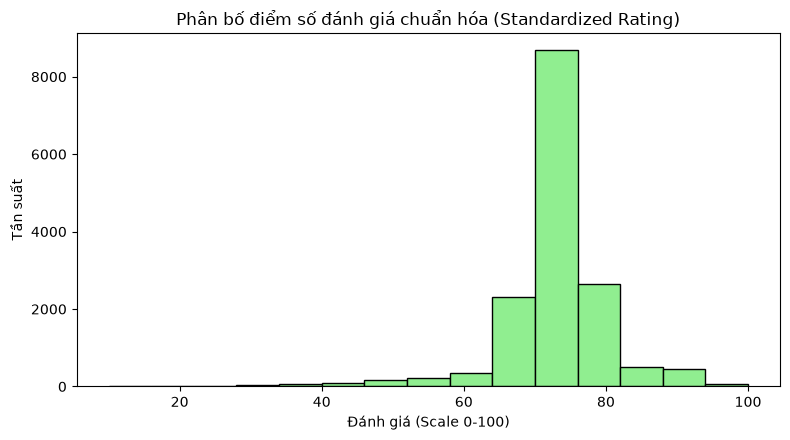

In [64]:
# Biểu đồ 2: Phân bố điểm Critic Score chuẩn hóa
plt.figure(figsize=(8, 4.5))
df_filtered['Rating'].plot(
    kind='hist', bins=15, color='lightgreen', edgecolor='black'
)
plt.title('Phân bố điểm số đánh giá chuẩn hóa (Standardized Rating)')
plt.xlabel('Đánh giá (Scale 0-100)')
plt.ylabel('Tần suất')
plt.tight_layout()
plt.show()

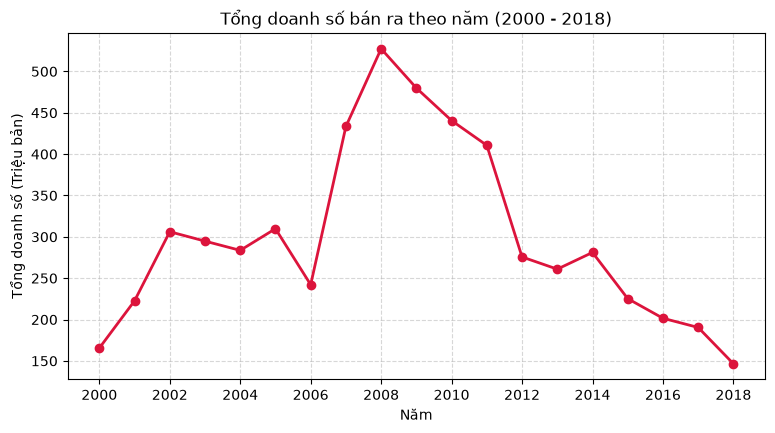

In [47]:
# Biểu đồ 3: Tổng doanh số theo năm
plt.figure(figsize=(9, 4.5))
yearly_sales = df_filtered.groupby('release_year')['total_sales'].sum()

plt.plot(
    yearly_sales.index,
    yearly_sales.values,
    marker='o',
    color='crimson',
    linewidth=2,
    markersize=6,
)
plt.title('Tổng doanh số bán ra theo năm (2000 - 2018)')
plt.xlabel('Năm')
plt.ylabel('Tổng doanh số (Triệu bản)')
plt.xticks(range(2000, 2019, 2))  #Hiển thị mốc năm cách nhau 2 năm
plt.grid(True, linestyle='--', alpha=0.5)

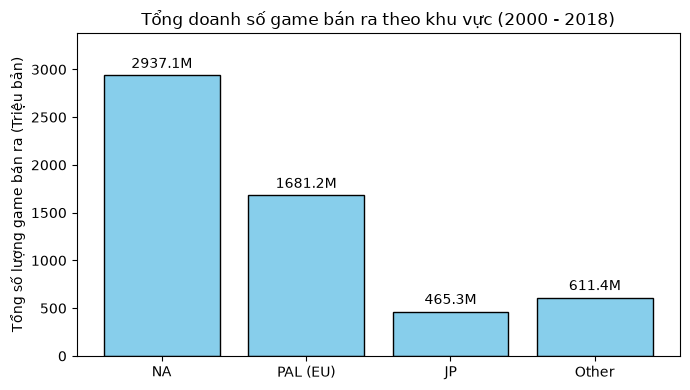

In [65]:
# Gom tổng doanh số 4 khu vực
regions = df_filtered[['na_sales', 'eu_sales', 'jp_sales', 'other_sales']].sum()

# Vẽ biểu đồ cột
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    ['NA', 'PAL (EU)', 'JP', 'Other'],
    regions.values,
    color='skyblue',
    edgecolor='black',
)

# Hiển thị số liệu trên đỉnh cột
ax.bar_label(bars, fmt='%.1fM', padding=3)

plt.title('Tổng doanh số game bán ra theo khu vực (2000 - 2018)')
plt.ylabel('Tổng số lượng game bán ra (Triệu bản)')
plt.ylim(0, regions.max() * 1.15)  

plt.tight_layout()
plt.show()

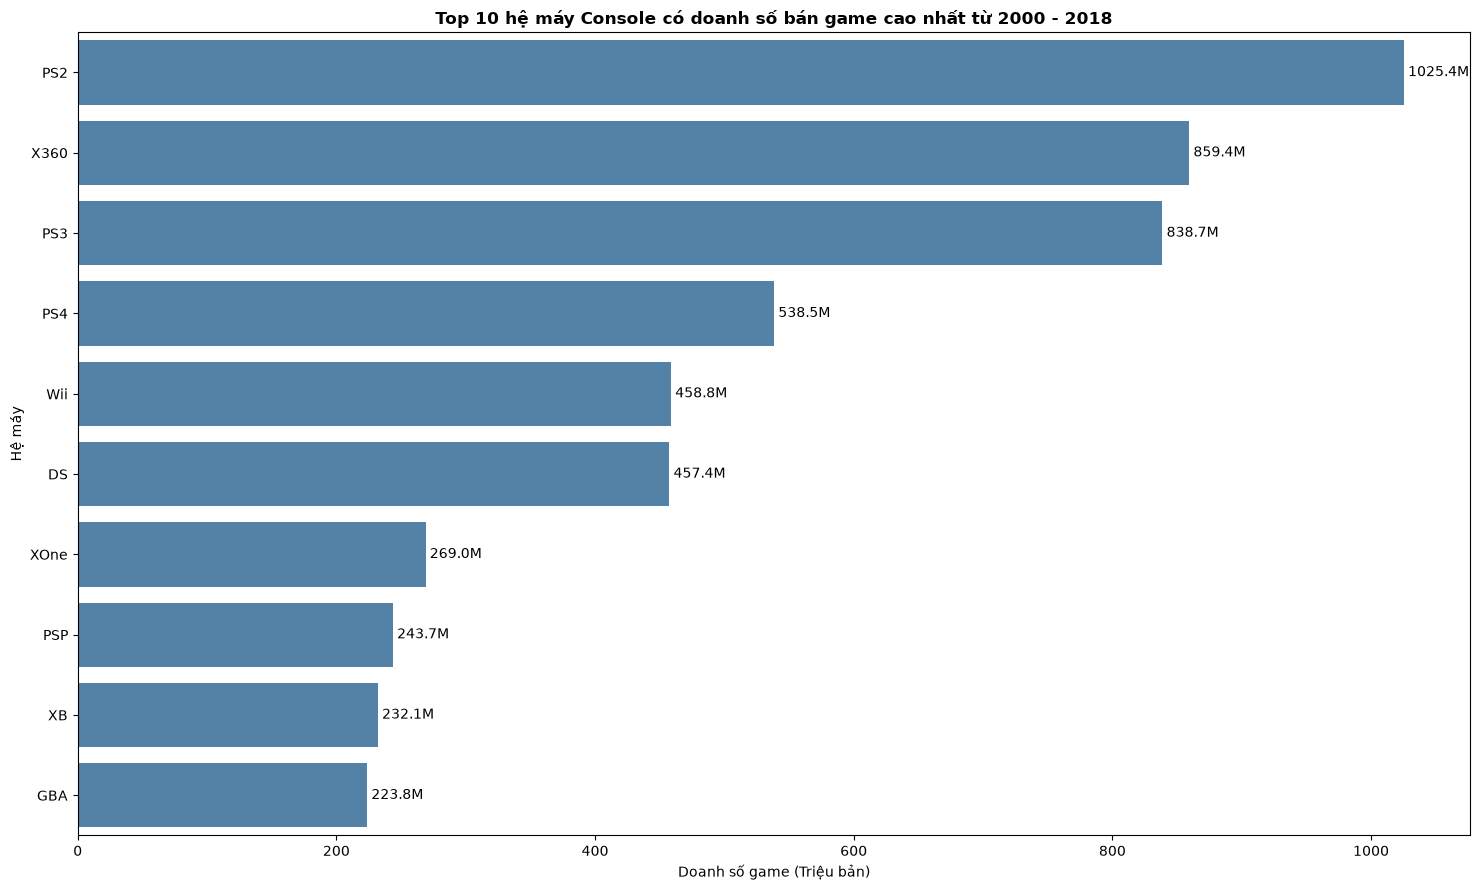

In [66]:
# Lấy Top 10
top10 = (
    df_filtered.groupby("platform")["total_sales"]
    .sum()
    .nlargest(10)
    .reset_index()
)

# Vẽ biểu đồ
plt.figure(figsize=(15, 9))
ax = sns.barplot(data=top10, x="total_sales", y="platform", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1fM", padding=3)

plt.title("Top 10 hệ máy Console có doanh số bán game cao nhất từ 2000 - 2018", fontweight="bold")
plt.xlabel("Doanh số game (Triệu bản)")
plt.ylabel("Hệ máy")
plt.tight_layout()
plt.show()

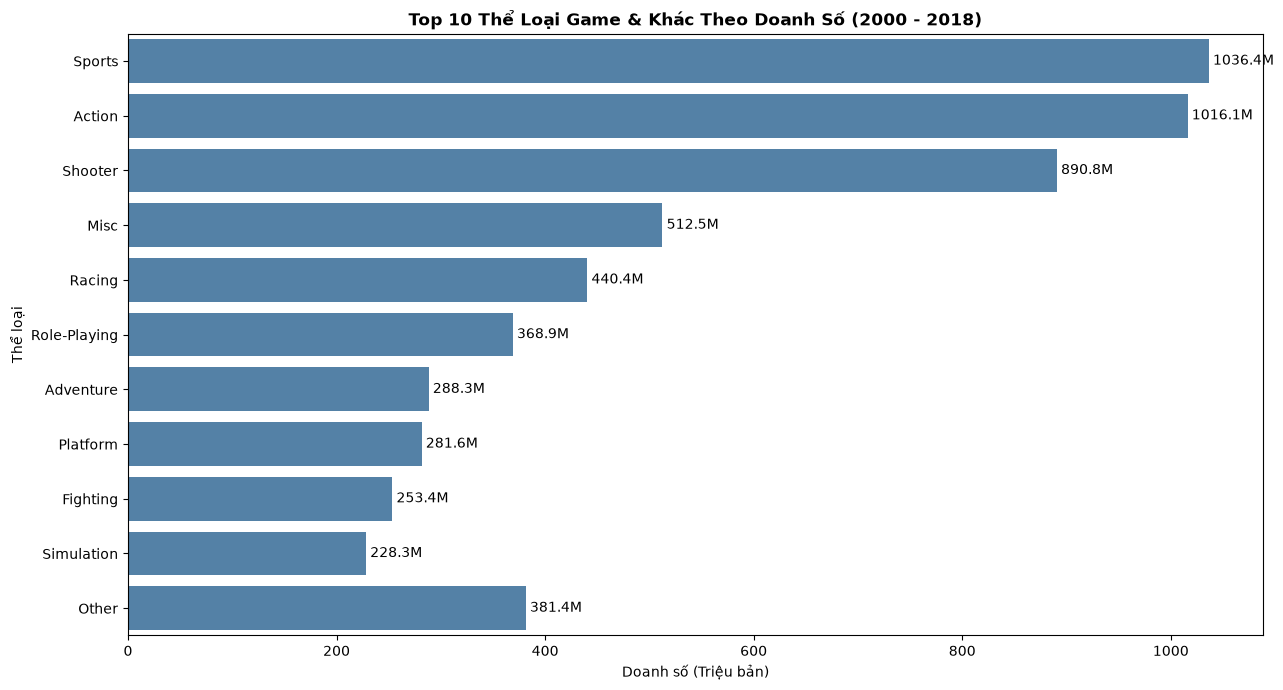

<ArrowStringArray>
[          'Action',          'Shooter', 'Action-Adventure',
           'Sports',     'Role-Playing',           'Racing',
            'Music',             'Misc',       'Simulation',
         'Platform',         'Fighting',        'Adventure',
           'Puzzle',              'MMO',          'Sandbox',
         'Strategy',            'Party',        'Education',
       'Board Game',     'Visual Novel']
Length: 20, dtype: str

In [67]:
#Gom nhóm tổng doanh số theo thể loại
genre_sales = (
    df_filtered.groupby("genre")["total_sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

#Tách Top 10 và gộp phần còn lại thành "Other"
top10 = genre_sales.head(10)
other_sales = genre_sales.iloc[10:]["total_sales"].sum()

if other_sales > 0:
    other_df = pd.DataFrame([{"genre": "Other", "total_sales": other_sales}])
    genre_final = pd.concat([top10, other_df], ignore_index=True)
else:
    genre_final = top10

#Vẽ biểu đồ
plt.figure(figsize=(13, 7))
ax = sns.barplot(data=genre_final, x="total_sales", y="genre", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1fM", padding=3)

plt.title(
    "Top 10 Thể Loại Game & Khác Theo Doanh Số (2000 - 2018)", fontweight="bold"
)
plt.xlabel("Doanh số (Triệu bản)")
plt.ylabel("Thể loại")
plt.tight_layout()
plt.show()
df_filtered['genre'].unique()